In [1]:
import pandas as pd
import numpy as np
import scanpy as sc
import matplotlib
import matplotlib.pyplot as plt
from   matplotlib import colors
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
import seaborn as sns
from pathlib import Path
import os
import pickle
import glob
import re
import anndata as ad
import sys
from scipy import stats
from statsmodels.stats.multitest import multipletests

from pandas.api.types import CategoricalDtype
from scipy.stats import kruskal, wilcoxon, rankdata, norm, mannwhitneyu
import importlib


In [2]:
#### Set plotting parameters
matplotlib.rcParams.update({
    "font.family":        "Liberation Sans",
    "pdf.fonttype":       42,   # TrueType → keeps glyphs grouped in Illustrator
    "ps.fonttype":        42,
    "axes.spines.top":    False,
    "axes.spines.right":  False,
    "axes.linewidth":     0.25,
    "xtick.major.width":  0.8,
    "ytick.major.width":  0.8,
    "xtick.minor.width":  0.5,
    "ytick.minor.width":  0.5,
    "xtick.major.size":   3.5,
    "ytick.major.size":   3.5,
    "axes.labelsize":     6,
    "xtick.labelsize":    6,
    "ytick.labelsize":    6,
    "legend.fontsize":    5,
    "axes.titlesize":     7,
    "figure.dpi":         300,
    "savefig.dpi":        300,
    "savefig.transparent": False,
    "savefig.bbox":       "tight",
    "savefig.pad_inches": 0.05,
})

### inches to points conversion
MM = 1 / 25.4

In [3]:
# ── File paths — edit these ───────────────────────────────────────────────────
ADATA_PATH      = 'seqFISH_discovery_cohort.h5ad'                       # AnnData object
DNA_MAT_PATH    = 'DNA_counts_filtered_rolled_annotated.csv'  # cell by DNA counts 
LOCI_PATH       = 'DNA_loci_orderd.csv'                 # loci → chromosome/arm mapping
CNA_PATH        = 'CNA_per_sample.csv'     # patient × loci CNA (malignant vs normal cells)

OUT_DIR = 'figures/'
os.makedirs(OUT_DIR, exist_ok=True)

print('Paths configured.')

Paths configured.


In [4]:
# Read data
adata = ad.read_h5ad(ADATA_PATH)

print(adata.obs['sample_group'].unique())
print(len(adata.obs['patient'].unique()), 'patients')
print(len(adata.obs['ROI'].unique()), 'samples')
adata

['GBM', 'future MT', 'Transformed', 'future stable | Rec', 'future stable | Init', 'Gliosarcoma']
Categories (6, object): ['GBM', 'Gliosarcoma', 'Transformed', 'future MT', 'future stable | Init', 'future stable | Rec']
23 patients
42 samples


AnnData object with n_obs × n_vars = 693013 × 1150
    obs: 'orig.ident', 'cell_area', 'center_x', 'center_y', 'patient', 'gender', 'grade', 'histology', 'IDH', 'cell_type', 'ROI', 'cellID', 'patient_id', 'state', 'sample_group', 'class'
    var: 'gene_names', 'gene_ids'
    uns: 'build'
    obsm: 'spatial'
    layers: 'counts'

In [5]:
# ── Load DNA files ─────────────────────────────────────────────────────────
dna_data   = pd.read_csv(DNA_MAT_PATH, index_col=0, dtype={'ROI':str})
loci_df    = pd.read_csv(LOCI_PATH)
print(len(dna_data['ROI'].unique()), 'samples')

dna_data.head(2)

30 samples


,block1.bin1,block1.bin2,block1.bin3,block1.bin4,block1.bin5,block1.bin6,block1.bin7,block1.bin8,block1.bin9,block1.bin10,...,block68.bin4,block68.bin5,cell_id,Malignant_status,ROI,cell_type,histology,center_x,center_y,sample_group
0,2.22,1.66,2.66,3.99,5.33,5.33,5.33,3.99,3.99,3.99,...,0.0,0.0,23_23,Normal,2122,Olig. normal,Oligo,3742.67,181.16,future MT
1,0.00,0.00,0.00,0.00,0.99,1.98,1.98,1.98,2.98,3.97,...,0.0,0.0,25_23,Normal,2122,Olig. normal,Oligo,1683.57,180.95,future MT


In [6]:
loci_df

,Unnamed: 0,blockbin,arm,chromosome,block_num,bin_num
0,0,block1_bin1,p,chr1,1,1
1,1,block1_bin2,p,chr1,1,2
2,2,block1_bin3,p,chr1,1,3
3,3,block1_bin4,p,chr1,1,4
4,4,block1_bin5,p,chr1,1,5
...,...,...,...,...,...,...
957,957,block68_bin1,q,chrY,68,1
958,958,block68_bin2,q,chrY,68,2
959,959,block68_bin3,q,chrY,68,3
960,960,block68_bin4,q,chrY,68,4


In [7]:
print(dna_data['ROI'].unique())
print(len(dna_data['ROI'].unique()), 'samples')
print(dna_data['sample_group'].unique())

['2122' '2543' '2683' '2789' '2830' '3097_1' '3209' '3364' '3557' '3754'
 '3825' '3883' '4250' '4494_1' '4494_2' '4523' '4555' '4590' '4668' '4904'
 '4970' '5121' '5201' '5272_1' '5272_2' '5538_1' '5538_2' '5541_1'
 '5541_2' '5597']
30 samples
['future MT' 'Transformed' 'GBM' 'future stable']


In [8]:
#check dna_data
print(dna_data['cell_type'].unique())
print(dna_data['sample_group'].unique())
print(len(dna_data['ROI'].unique()))
print(dna_data.shape[0])

['Olig. normal' 'AC' 'Neuron GABA.' 'Endothelial' 'OPC' 'Pericytes'
 'AC.like' 'Neuron Glut.' 'Microglia' 'VLMC' 'T' 'OPC.like Prolif.']
['future MT' 'Transformed' 'GBM' 'future stable']
30
301555


In [9]:
#match binblock format between loci_df and the other datafrmae
loci_df['blockbin'] = [f.replace('_', '.') for f in loci_df['blockbin']]
loci_df.head(2)

,Unnamed: 0,blockbin,arm,chromosome,block_num,bin_num
0,0,block1.bin1,p,chr1,1,1
1,1,block1.bin2,p,chr1,1,2


In [10]:
#read CNA df
sig_binblock = pd.read_csv(CNA_PATH, index_col=0, dtype={'patient_id':str})
sig_binblock.head(2)

,patient_id,dna_loc,control_mean,test_mean,log2_fc,p_value,padj
962,2122,block1.bin1,2.681438,1.522185,-0.816863,0.0,0.0
963,2122,block1.bin2,3.000747,1.711310,-0.810221,0.0,0.0


---
### Plot CNA patient profiles

In [11]:
"""
Publication-quality CNV heatmaps (one panel per cell `state`) sized for Nature.

Layout
------
- One heatmap panel per `state`; rows = samples, columns = genomic block.bins
  (ordered by `binblock_order`).
- Panel HEIGHTS are proportional to the number of samples in each state, so a
  single cell has the same physical height in every panel (this is the
  "row width in the order" bit).
- Two column-annotation strips on top, shared by every panel:
      * chromosome  (CHR_COLORS, mapped via loci_df['chromosome_true'])
      * arm         (p = lightgray, q = darkgray, via loci_df['arm'])
- One row-annotation strip per panel on the right: the matching `global_cnv`
  fraction for each sample (matched on sample/state/histology).
- Two shared colour bars on the far right: log2 fold-change and CNV fraction.

Expected inputs (as produced by your snippet)
---------------------------------------------
cnv_mat  : columns ['sample','histology','state', <binblock cols...>]  (reset_index of the pivot)
global_cnv : columns ['sample','state','histology','cnv']
loci_df  : columns ['blockbin','arm','chromosome_true', ...]
binblock_order : ordered iterable of blockbin names (the heatmap column order)
"""

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb, Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.patches import Patch

MM = 1 / 25.4  # mm -> inch

CHR_COLORS = {
    'chr1':  '#73b9a5', 'chr2':  '#c35653', 'chr3':  '#50729f',
    'chr4':  '#fea17b', 'chr5':  '#c5aedf', 'chr6':  '#d4af9e',
    'chr7':  '#fea8d4', 'chr8':  '#7e5679', 'chr9':  '#6ea9fd',
    'chr10': '#bd8985', 'chr11': '#d36d54', 'chr12': '#e4d177',
    'chr13': '#89aeb3', 'chr14': '#fec4a7', 'chr15': '#977d89',
    'chr16': '#637fd0', 'chr17': '#93581c', 'chr18': '#4bcbfe',
    'chr19': '#82e2dd', 'chr20': '#dea257', 'chr21': '#70715d',
    'chr22': '#009aa5', 'chrX':  '#c27869', 'chrY':  '#a893c6',
}
ARM_COLORS = {'p': 'lightgray', 'q': 'darkgray'}

TYPE2_COLORS = {
    'Astro': '#415483',
    'Oligo': '#59B599',
    'GBM':   '#B04534',
}

# ---------------------------------------------------------------- helpers ----
def _rgb_strip(keys, cmap_map):
    """1D iterable of keys -> (1, n, 3) RGB image for imshow."""
    rgb = np.array([to_rgb(cmap_map.get(k, 'white')) for k in keys])
    return rgb[np.newaxis, :, :]
 
 
def _runs(series):
    """Contiguous runs along an ordered series -> [(label, start, end_excl), ...]."""
    labels = list(series)
    out, start = [], 0
    for i in range(1, len(labels) + 1):
        if i == len(labels) or labels[i] != labels[start]:
            out.append((labels[start], start, i))
            start = i
    return out
 
 
def _order_rows(sub, mat, cluster_rows):
    """Return (positional row order, linkage Z or None) for one state panel."""
    if cluster_rows and mat.shape[0] > 2:
        try:
            from scipy.cluster.hierarchy import linkage, leaves_list
            from scipy.spatial.distance import pdist
            X = np.nan_to_num(mat, nan=0.0)
            Z = linkage(pdist(X, metric='euclidean'), method='average')
            return leaves_list(Z), Z
        except Exception:
            pass  # scipy missing -> fall through to a deterministic sort
    # fallback: group by histology, then heaviest CNV burden first
    order = sub.sort_values(['histology', 'cnv'],
                            ascending=[True, False]).index.to_numpy()
    return order, None
 
 
# ---------------------------------------------------------------- main -------
def plot_state_cnv_heatmaps(
        cnv_mat, global_cnv, loci_df, binblock_order,
        states=None,
        chr_colors=CHR_COLORS, arm_colors=ARM_COLORS,
        cmap='RdBu_r', vmin=-2, vmax=2,
        cnv_color='#555555', cnv_col='cnv',
        cluster_rows=True, annotate_type2=True, type2_colors=None,
        width_mm=180, max_height_mm=230, row_mm=2.4, dpi=300,
        show_row_labels=False, chrom_lines=True,
        show_dendrogram=True, dendro_width=0.05, dendro_lw=0.25,
        outfile=None):
    """
    Draw one CNV heatmap per state. Returns (fig, heat_axes).
 
    Key knobs
    ---------
    row_mm       : physical height of one sample row (mm). Auto-shrinks if the
                   figure would exceed max_height_mm.
    cluster_rows : hierarchically order samples within each panel (needs scipy).
                   Set False to order by histology then CNV burden.
    vmin/vmax    : log2FC colour limits; default symmetric 98th-percentile.
    show_row_labels : sample names on the left. Default False (hidden).
    show_dendrogram : draw the row-clustering tree in a thin left column.
                   Only appears where cluster_rows produced a linkage (panels
                   with > 2 samples); the sort-based fallback has no tree.
    dendro_width : width of the dendrogram column as a fraction of the heatmap
                   width (smaller = more squeezed; e.g. 0.03 for very thin).
    dendro_lw    : dendrogram line width in points (default 0.25).
    """
    # --- columns present, in the requested order ---------------------------
    cols = [c for c in binblock_order if c in cnv_mat.columns]
    if len(cols) < len(list(binblock_order)):
        print(f"[warn] {len(list(binblock_order)) - len(cols)} blockbins in "
              f"binblock_order are missing from cnv_mat and were dropped.")
 
    loc = (loci_df.drop_duplicates('blockbin')
                  .set_index('blockbin')
                  .reindex(cols))
    chrom, arm = loc['chromosome'], loc['arm']
    n_col = len(cols)
 
    # --- per-sample global CNV lookup --------------------------------------
    gc = global_cnv.set_index(['patient_id', 'sample_group', 'histology'])[cnv_col]
 
    if states is None:
        states = list(dict.fromkeys(cnv_mat['sample_group']))  # preserve appearance order
 
    # --- assemble each panel (subset, attach cnv, order rows) --------------
    panels = []
    for st in states:
        sub = cnv_mat[cnv_mat['sample_group'] == st].reset_index(drop=True)
        if sub.empty:
            continue
        sub['cnv'] = [gc.get((s, st, t), np.nan)
                      for s, t in zip(sub['patient_id'], sub['histology'])]
        mat = sub[cols].to_numpy(dtype=float)
        order, Z = _order_rows(sub, mat, cluster_rows)
        sub, mat = sub.iloc[order].reset_index(drop=True), mat[order]
        panels.append((st, sub, mat, Z))
 
    if not panels:
        raise ValueError("No data to plot for the requested states.")
 
    # --- colour scales ------------------------------------------------------
    allvals = np.concatenate([p[2].ravel() for p in panels])
    if vmax is None:
        vmax = float(np.nanpercentile(np.abs(allvals), 98)) or 1.0
    if vmin is None:
        vmin = -vmax
    cnv_all = np.concatenate([p[1]['cnv'].to_numpy(dtype=float) for p in panels])
    cnv_max = np.nanmax(cnv_all)
    cnv_max = cnv_max if np.isfinite(cnv_max) and cnv_max > 0 else 1.0  # shared bar limit
 
    # categorical colours for the histology row annotation (shared across panels)
    t2_levels = list(dict.fromkeys(cnv_mat['histology']))
    if type2_colors is None:
        base = plt.get_cmap('tab10').colors
        type2_colors = {lv: base[i % len(base)] for i, lv in enumerate(t2_levels)}
 
    # --- figure size (height driven by total sample count) -----------------
    n_samp = [p[2].shape[0] for p in panels]
    total = sum(n_samp)
    ann_units = 0.9                      # each top strip ~0.9 sample-rows tall
    width_in = width_mm * MM
    row_h = row_mm * MM
    height_in = row_h * (total + 2 * ann_units) + 0.9    # +margins
    max_h_in = max_height_mm * MM
    if height_in > max_h_in:
        height_in = max_h_in
 
    rc = {'font.size': 7, 'font.family': 'sans-serif',
          'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
          'axes.linewidth': 0.5, 'pdf.fonttype': 42, 'ps.fonttype': 42}
    with plt.rc_context(rc):
        fig = plt.figure(figsize=(width_in, height_in), dpi=dpi)
        # optional thin dendrogram column on the far left
        dcol_w = dendro_width if show_dendrogram else 0.0
        dendro_col = 0 if show_dendrogram else None
        base = 1 if show_dendrogram else 0
        if annotate_type2:
            wr = ([dcol_w] if show_dendrogram else []) + [0.03, 1.0, 0.11]
            t2_col, heat_col, bar_col = base, base + 1, base + 2
        else:
            wr = ([dcol_w] if show_dendrogram else []) + [1.0, 0.11]
            t2_col, heat_col, bar_col = None, base, base + 1
        ncols = len(wr)
        gs = fig.add_gridspec(
            nrows=2 + len(panels), ncols=ncols,
            height_ratios=[ann_units, ann_units] + n_samp,
            width_ratios=wr,
            left=0.13, right=0.86, top=0.92, bottom=0.06,
            hspace=0.10, wspace=0.03)
 
        xlim = (-0.5, n_col - 0.5)
        runs = _runs(chrom)
        centers = [(s + e - 1) / 2 for _, s, e in runs]
        bounds = [e - 0.5 for _, _, e in runs[:-1]]
 
        # chromosome labels (text only, no colour fill) -------------------
        ax_chr = fig.add_subplot(gs[0, heat_col])
        ax_chr.set_xlim(xlim); ax_chr.set_ylim(0, 1)
        ax_chr.set_xticks([]); ax_chr.set_yticks([])
        for sp in ax_chr.spines.values():
            sp.set_visible(False)
        for (c, _, _), cx in zip(runs, centers):
            ax_chr.text(cx, 0.5, c.replace('chr', ''),
                        ha='center', va='center', fontsize=5)
        for b in bounds:                       # faint separators between labels
            ax_chr.axvline(b, color='0.8', lw=0.4)
        ax_chr.set_ylabel('chr', rotation=0, ha='right', va='center',
                          fontsize=6, labelpad=6)
 
        # arm strip --------------------------------------------------------
        ax_arm = fig.add_subplot(gs[1, heat_col])
        ax_arm.imshow(_rgb_strip(arm, arm_colors), aspect='auto',
                      extent=[-0.5, n_col - 0.5, 0, 1])
        ax_arm.set_xlim(xlim); ax_arm.set_xticks([]); ax_arm.set_yticks([])
        ax_arm.set_ylabel('arm', rotation=0, ha='right', va='center',
                          fontsize=6, labelpad=6)
 
        # heatmap panels + cnv strips -------------------------------------
        heat_axes = []
        for k, (st, sub, mat, Z) in enumerate(panels):
            r = 2 + k
            nr = mat.shape[0]
            lab = show_row_labels if show_row_labels is not None else (nr <= 40)
 
            # thin row dendrogram on the far left (only where we have a linkage)
            if show_dendrogram and dendro_col is not None and Z is not None:
                from scipy.cluster.hierarchy import dendrogram
                axd = fig.add_subplot(gs[r, dendro_col])
                dd = dendrogram(Z, orientation='left', no_plot=True,
                                no_labels=True, color_threshold=0)
                xmax = max((x for xs in dd['dcoord'] for x in xs), default=1.0)
                for xs, ys in zip(dd['dcoord'], dd['icoord']):
                    axd.plot(np.asarray(xs),
                             (np.asarray(ys) - 5.0) / 10.0,   # scipy leaf units -> row index
                             color='0.2', lw=dendro_lw, solid_capstyle='round')
                axd.set_ylim(nr - 0.5, -0.5)                  # match heatmap orientation
                axd.set_xlim(xmax * 1.02, 0)                  # root at left, leaves at right
                axd.axis('off')
 
            # histology categorical strip on the left
            axL = None
            if annotate_type2:
                axt = fig.add_subplot(gs[r, t2_col])
                strip = np.array([to_rgb(type2_colors.get(t, 'white'))
                                  for t in sub['histology']]).reshape(nr, 1, 3)
                axt.imshow(strip, aspect='auto', interpolation='nearest',
                           extent=[0, 1, nr - 0.5, -0.5])
                axt.set_xticks([])
                if k == 0:
                    axt.set_title('histology', fontsize=4.5, pad=2)
                axL = axt
 
            axh = fig.add_subplot(gs[r, heat_col])
            axh.imshow(mat, aspect='auto', cmap=cmap, vmin=vmin, vmax=vmax,
                       interpolation='nearest',
                       extent=[-0.5, n_col - 0.5, nr - 0.5, -0.5])
            axh.set_xlim(xlim); axh.set_xticks([])
            if axL is None:            # no strip -> labels live on the heatmap
                axL = axh
            else:
                axh.set_yticks([])
            axL.set_ylabel(st, rotation=90, va='center', fontsize=7,
                           fontweight='bold', labelpad=3)
            if lab:
                axL.set_yticks(range(nr))
                axL.set_yticklabels(sub['patient_id'], fontsize=4)
                axL.tick_params(length=0)
            else:
                axL.set_yticks([])
            if chrom_lines:
                for b in bounds:
                    axh.axvline(b, color='white', lw=0.5)
            heat_axes.append(axh)
 
            # global CNV as horizontal bars, shared x-limits across panels
            axc = fig.add_subplot(gs[r, bar_col])
            axc.barh(np.arange(nr), sub['cnv'].to_numpy(dtype=float),
                     height=0.85, color=cnv_color, linewidth=0)
            axc.set_xlim(0, cnv_max)
            axc.set_ylim(nr - 0.5, -0.5)          # align with heatmap rows
            axc.set_yticks([])
            axc.spines[['top', 'right']].set_visible(False)
            if k == len(panels) - 1:
                axc.set_xticks([0, cnv_max])
                axc.set_xticklabels(['0', f'{cnv_max:.2g}'], fontsize=4)
                axc.tick_params(length=1.5, pad=1)
                axc.set_xlabel('CNV frac', fontsize=5)
            else:
                axc.set_xticks([])
            if k == 0:
                axc.set_title('CNV frac', fontsize=4.5, pad=2)
 
        heat_axes[-1].set_xlabel('genomic bin (block.bin)', fontsize=6)
 
        # log2 fold-change colour bar (right margin) ----------------------
        cax1 = fig.add_axes([0.885, 0.38, 0.012, 0.28])
        cb1 = fig.colorbar(ScalarMappable(Normalize(vmin, vmax), cmap), cax=cax1)
        cb1.set_label('log2 FC', fontsize=6); cb1.ax.tick_params(labelsize=5)
 
        if annotate_type2:
            handles = [Patch(facecolor=type2_colors[l], edgecolor='none', label=str(l))
                       for l in t2_levels]
            fig.legend(handles=handles, title='histology', fontsize=5, title_fontsize=6,
                       frameon=False, loc='upper left', bbox_to_anchor=(0.875, 0.30),
                       handlelength=1.0, handleheight=1.0, borderpad=0.3,
                       labelspacing=0.35)
 
        if outfile:
            fig.savefig(outfile, dpi=dpi, bbox_inches='tight')
 
    return fig, heat_axes

In [12]:
#organize matrix
common_samples = np.intersect1d(sig_binblock['patient_id'].unique(), dna_data['ROI'].unique())
sig_binblock = sig_binblock.loc[sig_binblock['patient_id'].isin(common_samples),]
sample_dict = dna_data[['ROI','sample_group','histology']].drop_duplicates().set_index('ROI')
sample_dict = sample_dict.loc[sample_dict.index.isin(common_samples),]
sig_binblock = sig_binblock.merge(sample_dict, left_on='patient_id', right_index=True, how='left')

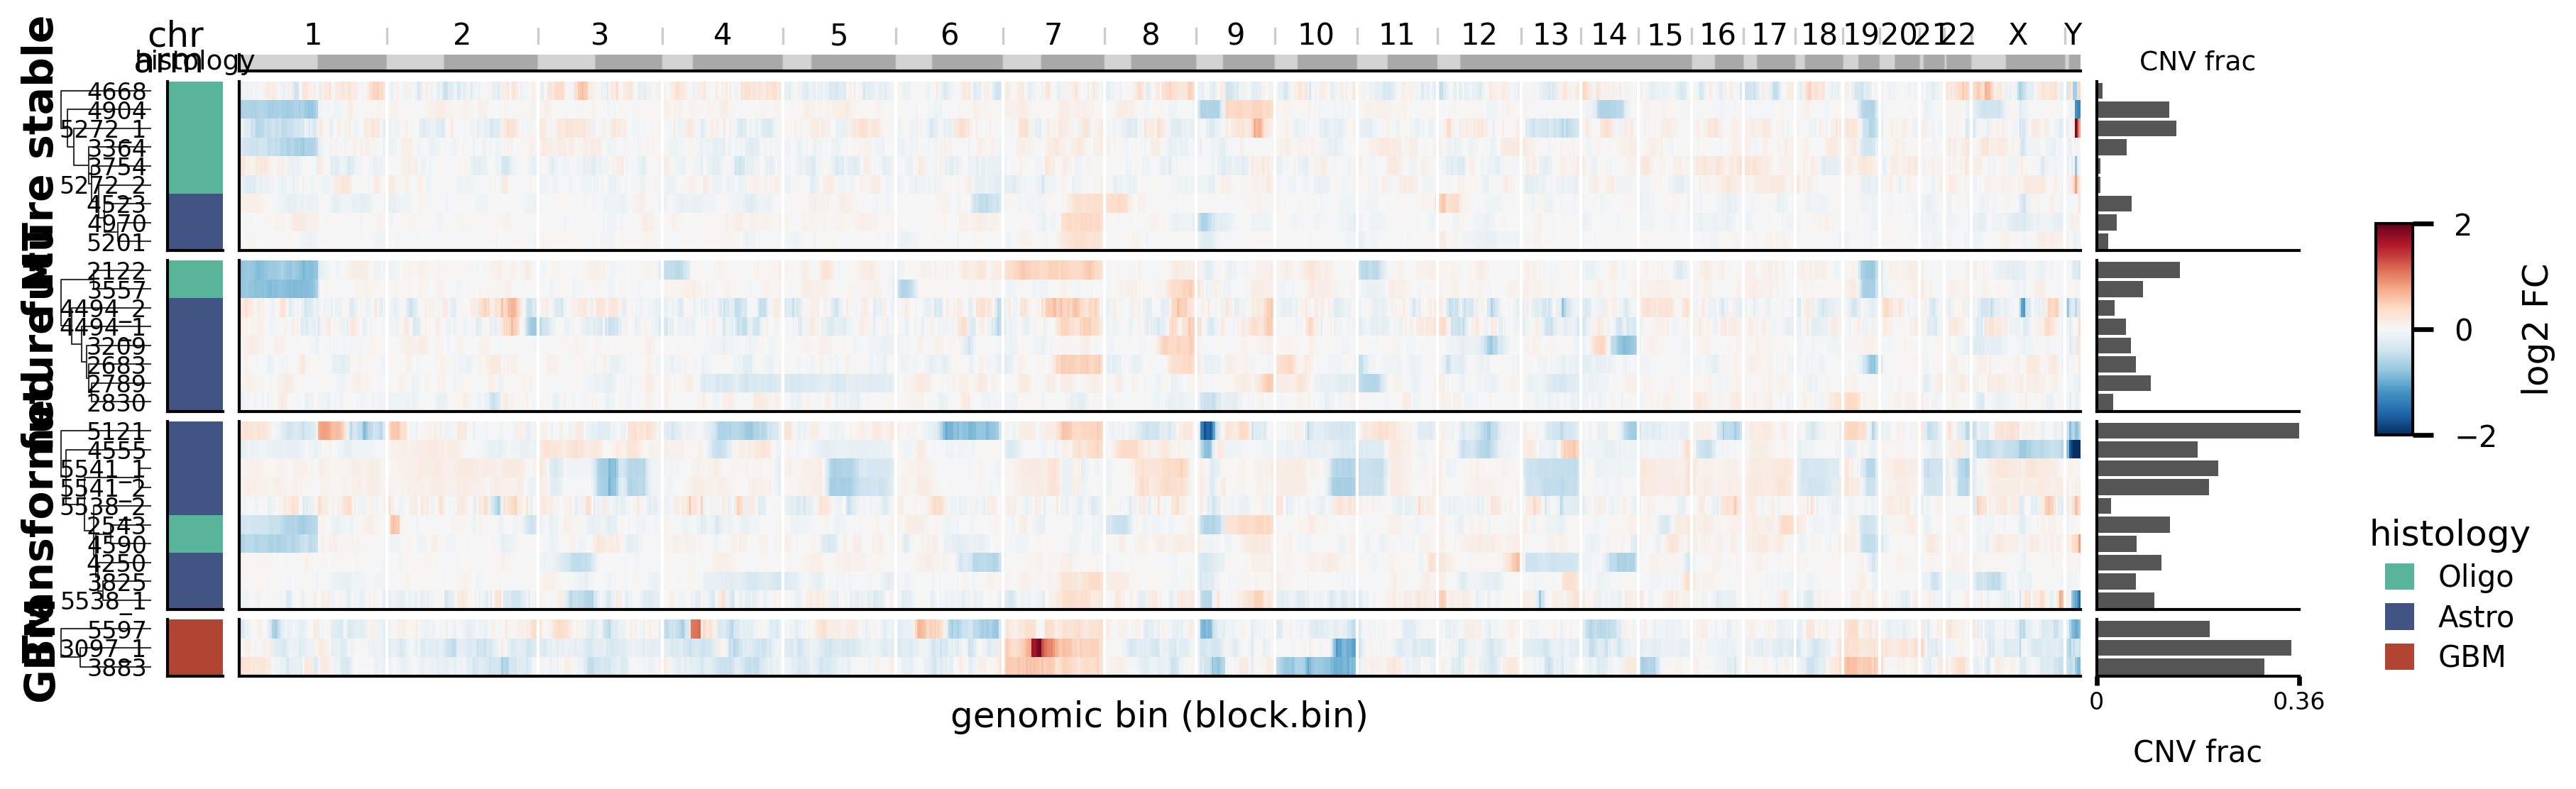

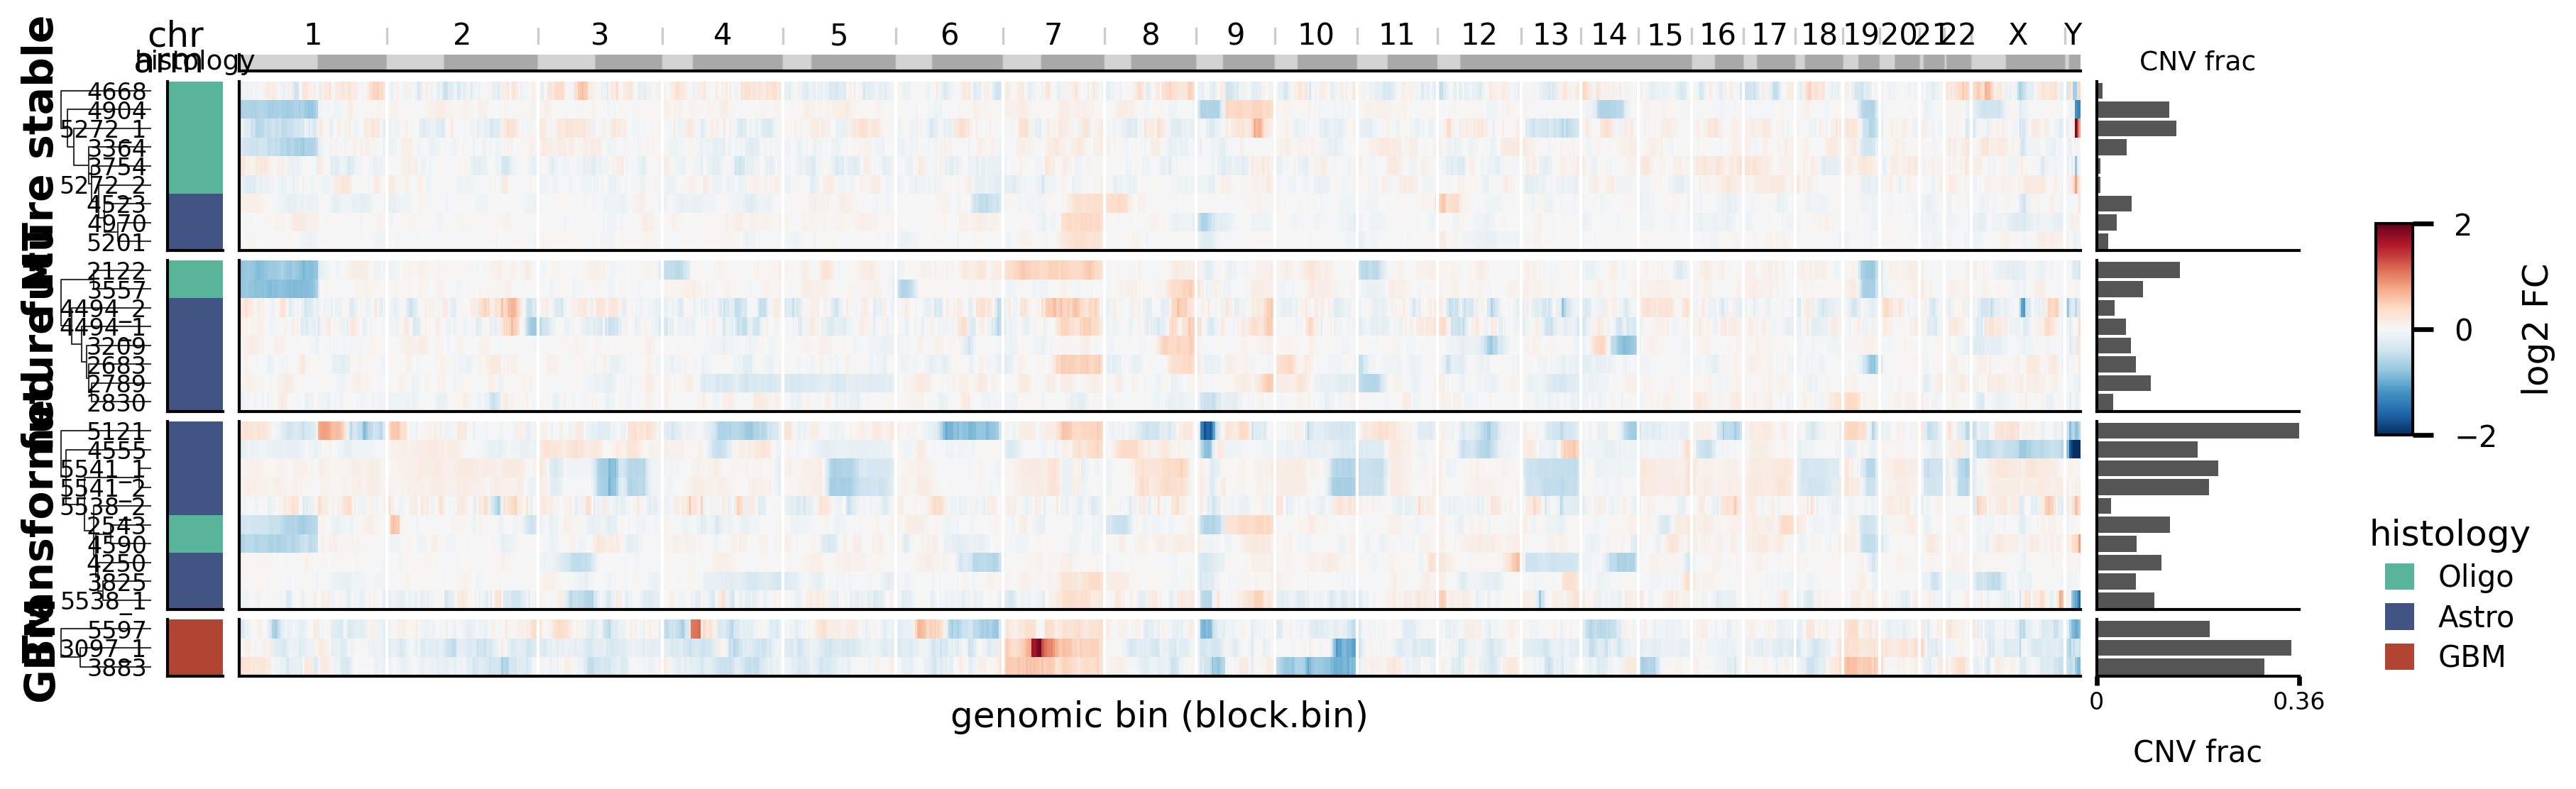

In [13]:
thresh_l=0.25
thresh_p=0.001
n_loc   = len(loci_df['blockbin'].unique())
binblock_order = loci_df['blockbin'].unique()
sig_binblock['cnv'] = 0
#sig_binblock['cnv_dn'] = 0
sig_binblock.loc[ (np.abs(sig_binblock['log2_fc']) >= thresh_l) & (sig_binblock['padj'] <= thresh_p),'cnv'] = 1

global_cnv = sig_binblock.groupby(['patient_id','sample_group','histology'], observed=True)['cnv'].apply(lambda x: sum(x) / n_loc).reset_index()
cnv_mat = sig_binblock.pivot_table(index=['patient_id','histology','sample_group'], columns='dna_loc', values='log2_fc').reset_index()

IDs=list(global_cnv.loc[~global_cnv['sample_group'].isin(['not_available']),'patient_id'])

fig, _ = plot_state_cnv_heatmaps(
        cnv_mat[cnv_mat['patient_id'].isin(IDs)], global_cnv[global_cnv['patient_id'].isin(IDs)], loci_df, binblock_order,
        states=['future stable','future MT','Transformed','GBM'],
        chr_colors=CHR_COLORS, arm_colors=ARM_COLORS,
        cmap='RdBu_r', vmin=-2, vmax=2,
        cnv_color='#555555', cnv_col='cnv',
        cluster_rows=True, annotate_type2=True, type2_colors=TYPE2_COLORS,
        width_mm=183, max_height_mm=45, row_mm=2.4, dpi=600,
        show_row_labels=True, chrom_lines=True,
        show_dendrogram=True, dendro_width=0.05, dendro_lw=0.25,
        outfile=f'{OUT_DIR}/Fig2_cnv_map.pdf')

fig

In [14]:
STATE_COLORS = {
    'future stable': '#E69E84',
    'future stable Rec': '#E69E84',
    'future MT':     '#724C6D',
    'Transformed':   '#C44E52',
    'GBM':           '#8172B3',
}

STATE_LABEL = {
    'future stable': 'stable',
    'future MT':     'MT',
    'Transformed':   'Transformed',
    'GBM':           'GBM',
}


def _box_strip(ax, values_per_pos, positions, colors,
               box_w=0.5, ptsize=12, jitter=0.08, rng=None):
    rng = rng if rng is not None else np.random.default_rng(0)
    for vals, pos, col in zip(values_per_pos, positions, colors):
        vals = np.asarray(vals, float); vals = vals[np.isfinite(vals)]
        if vals.size == 0:
            continue
        if vals.size >= 2:
            bp = ax.boxplot([vals], positions=[pos], widths=box_w,
                            patch_artist=True, showfliers=False, manage_ticks=False,
                            medianprops=dict(color='black', lw=1.0),
                            boxprops=dict(lw=0.6), whiskerprops=dict(lw=0.6),
                            capprops=dict(lw=0.6))
            for bx in bp['boxes']:
                bx.set_facecolor(col); bx.set_alpha(0.30); bx.set_edgecolor(col)
        jit = (rng.random(vals.size) - 0.5) * 2 * jitter
        ax.scatter(pos + jit, vals, s=ptsize, color=col,
                   edgecolor='white', linewidth=0.4, zorder=3, alpha=0.95)


def _bh(pvals):
    p = np.asarray(pvals, float); m = p.size
    o = np.argsort(p)
    q = np.empty(m)
    q[o] = np.minimum.accumulate((p[o] * m / np.arange(1, m + 1))[::-1])[::-1]
    return np.clip(q, 0, 1)


def pairwise_mwu(df, states, value='cnv', state_col='sample_group'):
    """Pairwise two-sided Mann-Whitney across states, BH-adjusted. Tidy DataFrame."""
    groups = {s: df.loc[df[state_col] == s, value].to_numpy(float) for s in states}
    groups = {s: v[np.isfinite(v)] for s, v in groups.items()}
    rows, ps = [], []
    for i in range(len(states)):
        for j in range(i + 1, len(states)):
            a, b = groups[states[i]], groups[states[j]]
            if a.size and b.size and np.ptp(np.concatenate([a, b])) > 0:
                U, p = mannwhitneyu(a, b, alternative='two-sided')
            else:
                U, p = np.nan, np.nan
            rows.append({'stateA': states[i], 'stateB': states[j],
                         'meanA': np.mean(a), 'meanB': np.mean(b),
                         'sdA': np.std(a), 'sdB': np.std(b),
                         'i': i, 'j': j, 'U': U, 'p': p})
            ps.append(p)
    out = pd.DataFrame(rows)
    out['q'] = _bh(out['p'].to_numpy())
    return out


def plot_cnv(
        df, state_order=('future stable', 'future MT', 'future stable Rec', 'Transformed', 'GBM'),
        state_colors=STATE_COLORS, state_label=STATE_LABEL,
        width_mm=85, height_mm=62, dpi=300, outfile=None, verbose=True):
    rng = np.random.default_rng(0)
    state_order = list(state_order)

    rc = {'font.size': 7, 'font.family': 'sans-serif',
          'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
          'axes.linewidth': 0.6, 'pdf.fonttype': 42, 'ps.fonttype': 42}
    with plt.rc_context(rc):
        fig, ax = plt.subplots(figsize=(width_mm * MM, height_mm * MM), dpi=dpi)

        # ---------------- box + strip by state ----------------
        vals = [df.loc[df.sample_group == s, 'cnv'].values for s in state_order]
        cols = [state_colors.get(s, '#888888') for s in state_order]
        _box_strip(ax, vals, np.arange(len(state_order)), cols,
                   box_w=0.55, ptsize=13, jitter=0.09, rng=rng)
        ax.set_xticks(np.arange(len(state_order)))
        ax.set_xticklabels([state_label.get(s, s) for s in state_order],
                           rotation=25, ha='right', fontsize=6)
        ax.set_ylabel('CNA burden', fontsize=7)
        ax.set_xlim(-0.6, len(state_order) - 0.4)
        ax.margins(y=0.10)
        ax.set_ylim(top=np.nanmax(df['cnv'].values) * 1.45)
        for sp in ('top', 'right'):
            ax.spines[sp].set_visible(False)

        # omnibus + pairwise post-hoc: which states differ
        valid = [s for s in state_order if (df.sample_group == s).sum() >= 1]
        posthoc = None
        if len(valid) >= 2:
            try:
                kp = kruskal(*[df.loc[df.sample_group == s, 'cnv'].values
                               for s in valid]).pvalue
                ax.set_title(f'CNV by state  (Kruskal p={kp:.3f})', fontsize=6.5)
            except ValueError:
                ax.set_title('CNV by state', fontsize=6.5)
            posthoc = pairwise_mwu(df, valid)
            if verbose:
                print("\nPairwise Mann-Whitney across states (BH-corrected):")
                print(posthoc[['stateA', 'stateB', 'U', 'p', 'q']].to_string(index=False))
            # brackets for significant pairs, stacked above the data
            pos = {s: k for k, s in enumerate(state_order)}
            ytop = np.nanmax(df['cnv'].values)
            step = ytop * 0.09
            sig = posthoc[posthoc['q'] < 0.05].copy()
            sig['span'] = (sig['stateB'].map(pos) - sig['stateA'].map(pos)).abs()
            sig = sig.sort_values('span')            # short brackets lowest
            level = 0
            for _, rr in sig.iterrows():
                xa, xb = pos[rr['stateA']], pos[rr['stateB']]
                y = ytop + step * (1 + level)
                ax.plot([xa, xa, xb, xb],
                        [y, y + step * 0.25, y + step * 0.25, y],
                        color='black', lw=0.6)
                st = '***' if rr['q'] < 1e-3 else '**' if rr['q'] < 1e-2 else '*'
                ax.text((xa + xb) / 2, y + step * 0.25, st,
                        ha='center', va='bottom', fontsize=7)
                level += 1

        if outfile:
            fig.savefig(outfile, dpi=dpi, bbox_inches='tight')
    return fig, posthoc


Pairwise Mann-Whitney across states (BH-corrected):
       stateA      stateB    U        p        q
future stable   future MT 23.0 0.228763 0.228763
future stable Transformed 14.0 0.012724 0.032088
future stable         GBM  0.0 0.016044 0.032088
    future MT Transformed 17.5 0.050493 0.075740
    future MT         GBM  0.0 0.012121 0.032088
  Transformed         GBM  4.0 0.076923 0.092308


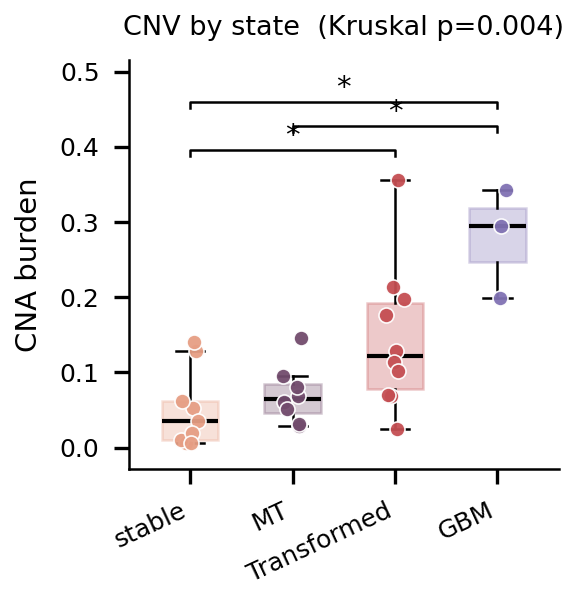

In [15]:
fig, dunn = plot_cnv(global_cnv, 
                             width_mm=47, 
                             height_mm=45,
                             state_order=('future stable', 'future MT', 'Transformed', 'GBM'),
                             outfile=f'{OUT_DIR}/Fig2_cnv_boxplot.pdf')
fig

___
### Plot single cell chromosome changes

In [16]:
from spatial_score_analysis import plot_celltype_overview

from dna_loci_significance import correct_by_normals_loci

In [17]:
#read chromosome-arm level loci fractions
loci_c = pd.read_csv('DNA_arm_level_loci_fractions_corrected.csv', index_col=0, dtype={'sample_id' : str})
loci_c.head(2)

,sample_id,cell_id,class,total_loci,cell_type,loci_frac_chr10_p,loci_frac_chr10_q,loci_frac_chr11_p,loci_frac_chr11_q,loci_frac_chr12_p,...,loci_frac_chr6_p,loci_frac_chr6_q,loci_frac_chr7_p,loci_frac_chr7_q,loci_frac_chr8_p,loci_frac_chr8_q,loci_frac_chr9_p,loci_frac_chr9_q,loci_frac_chrX_p,loci_frac_chrX_q
0,2122,10001_23,normal,1166,Neuron GABA.,0.323007,-0.151107,0.213944,-0.239646,0.555645,...,-0.563694,-0.059913,-0.689834,0.804104,-0.340646,0.420862,0.038968,-0.222182,-0.465567,-0.224739
1,2122,10002_23,LGG_MT,868,OPC,0.721444,-0.563176,-0.045819,0.146918,-0.052720,...,0.360675,-0.613072,-0.106429,0.058418,0.915912,-0.418961,1.105058,0.510988,-1.257252,0.226095


In [18]:
# plot specific chr_arm on one sample
SAMPLE_ID = '2122'
CHR_ARM = ['loci_frac_chr1_p', 'loci_frac_chr7_q']

loci_s = loci_c.loc[loci_c['sample_id'].astype(str) == SAMPLE_ID].set_index('cell_id')
loci_s.index = loci_s.index.astype(str)

adata_sub = adata[adata.obs['cellID'].astype(str).isin(loci_s.index)].copy()
adata_sub.obs_names = adata_sub.obs['cellID'].astype(str).values

for arm in CHR_ARM:
    adata_sub.obs[arm] = loci_s[arm].reindex(adata_sub.obs_names).to_numpy()

adata_sub.obs

,orig.ident,cell_area,center_x,center_y,patient,gender,grade,histology,IDH,cell_type,ROI,cellID,patient_id,state,sample_group,class,loci_frac_chr1_p,loci_frac_chr7_q
23_23,SeuratProject,355.45,3742.67,181.16,p8,M,II,Oligo,Mut,Olig. normal,2122,23_23,2122,future MT,future MT,normal,-0.179412,0.065431
25_23,SeuratProject,217.06,1683.57,180.95,p8,M,II,Oligo,Mut,Olig. normal,2122,25_23,2122,future MT,future MT,normal,0.539982,0.017377
26_23,SeuratProject,205.92,1896.33,183.14,p8,M,II,Oligo,Mut,Olig. normal,2122,26_23,2122,future MT,future MT,normal,-0.004830,-0.625822
27_23,SeuratProject,104.08,1647.09,186.05,p8,M,II,Oligo,Mut,AC,2122,27_23,2122,future MT,future MT,normal,-0.275752,-1.322721
30_23,SeuratProject,246.86,1726.81,193.32,p8,M,II,Oligo,Mut,Neuron Glut.,2122,30_23,2122,future MT,future MT,normal,-0.511361,0.314555
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13659_23,SeuratProject,118.77,2071.26,2719.62,p8,M,II,Oligo,Mut,Endothelial,2122,13659_23,2122,future MT,future MT,normal,-2.133502,0.362883
13660_23,SeuratProject,132.98,2059.10,2722.53,p8,M,II,Oligo,Mut,Microglia,2122,13660_23,2122,future MT,future MT,normal,1.727892,1.839428
13664_23,SeuratProject,339.23,1998.08,2744.56,p8,M,II,Oligo,Mut,Neuron Glut.,2122,13664_23,2122,future MT,future MT,normal,-0.585818,-0.384520
13665_23,SeuratProject,260.23,2019.08,2743.31,p8,M,II,Oligo,Mut,Neuron Glut.,2122,13665_23,2122,future MT,future MT,normal,0.802263,0.175895


Saved: figures/2122_overview_chromosome_arms.pdf


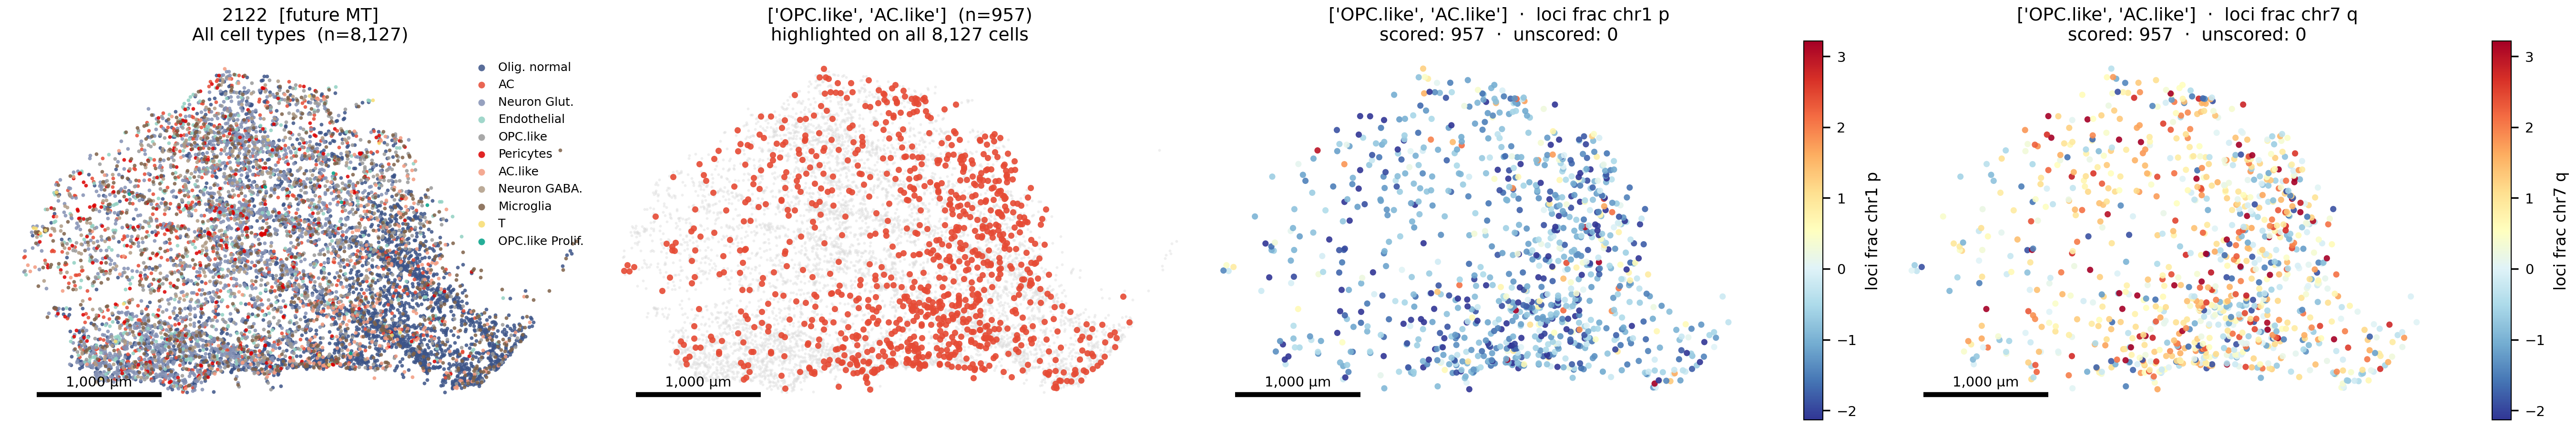

In [19]:
fig = plot_celltype_overview(
    adata_sub,
    sample_col = 'ROI',
    sample_id   = SAMPLE_ID,
    celltype_col = 'cell_type',
    cell_type   = ['OPC.like',"AC.like"],
    score_cols  = CHR_ARM,
    highlight_color = "#E64B35",
    highlight_size = 10,
    scalebar_um = 1000,
    out_path    = f"{OUT_DIR}{SAMPLE_ID}_overview_chromosome_arms.pdf",
)
fig

In [20]:
# ── correct binblock loci ─────────────────────────────────────────────────────────────
print("\nRunning corrections (binblock loci...)")
meta_cols         = ["ROI", "cell_type", "histology","Malignant_status","cell_id", "sample_group", "center_x",	"center_y"]
method = 'zscore'
normal_cell_types = ['Olig. normal', 'Microglia']
alpha=0.05
corrected_loci = correct_by_normals_loci(
    dna_data, 
    id_col = 'ROI',
    method=method,
    normal_cell_types=normal_cell_types,
    meta_cols=meta_cols,
)


Running corrections (binblock loci...)
  Correction done [zscore]. Null = 0.0. 30/30 samples corrected.


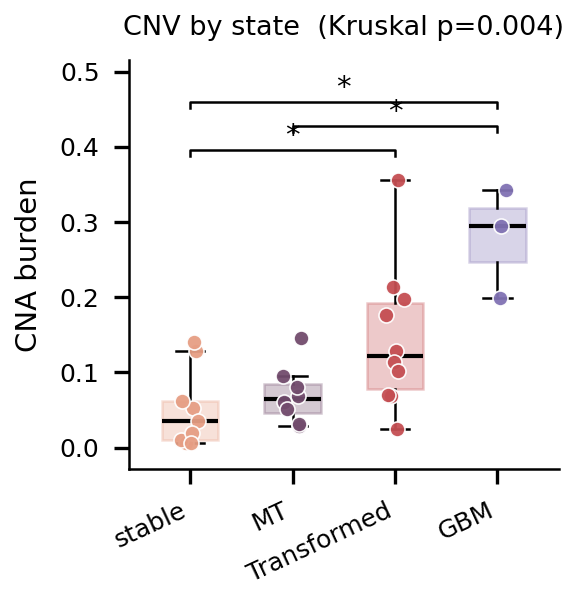

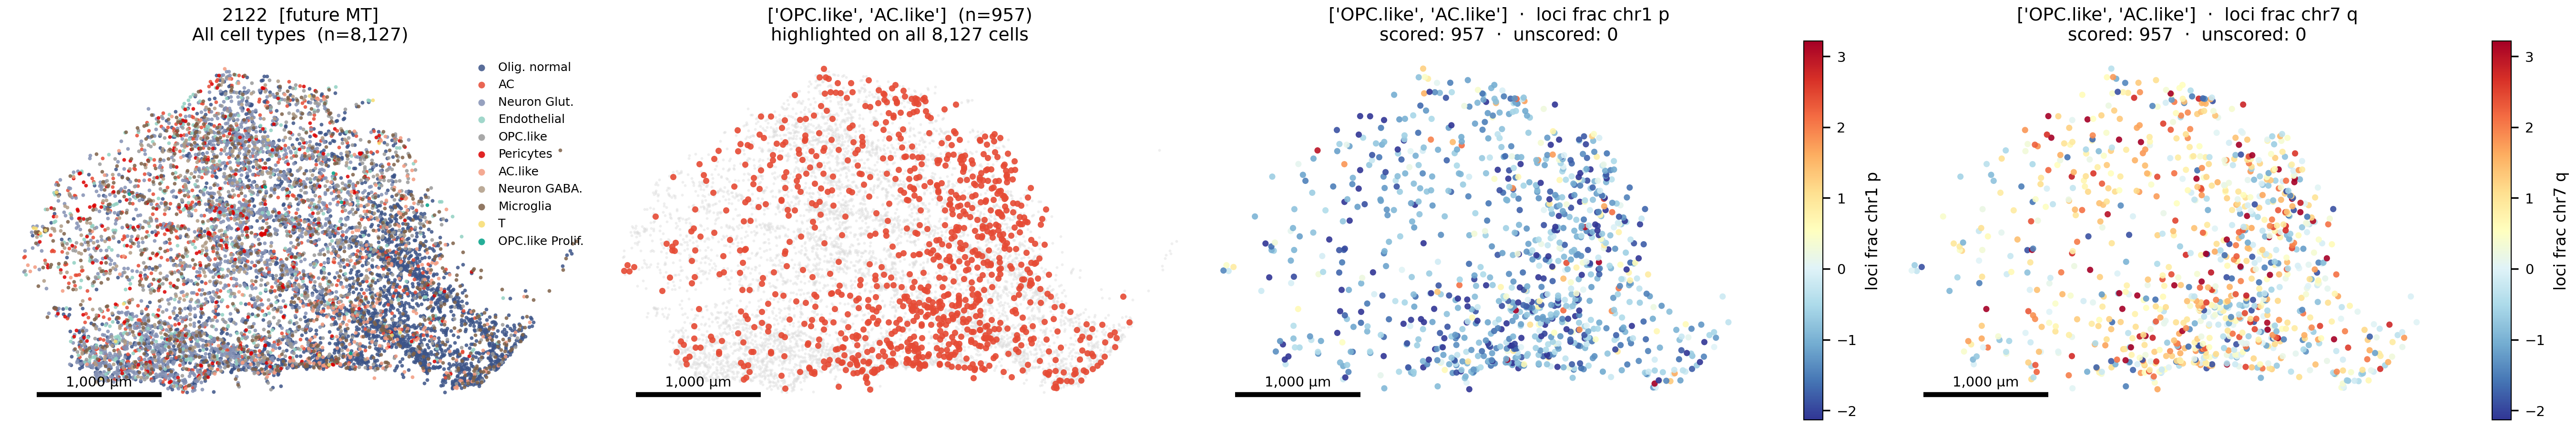

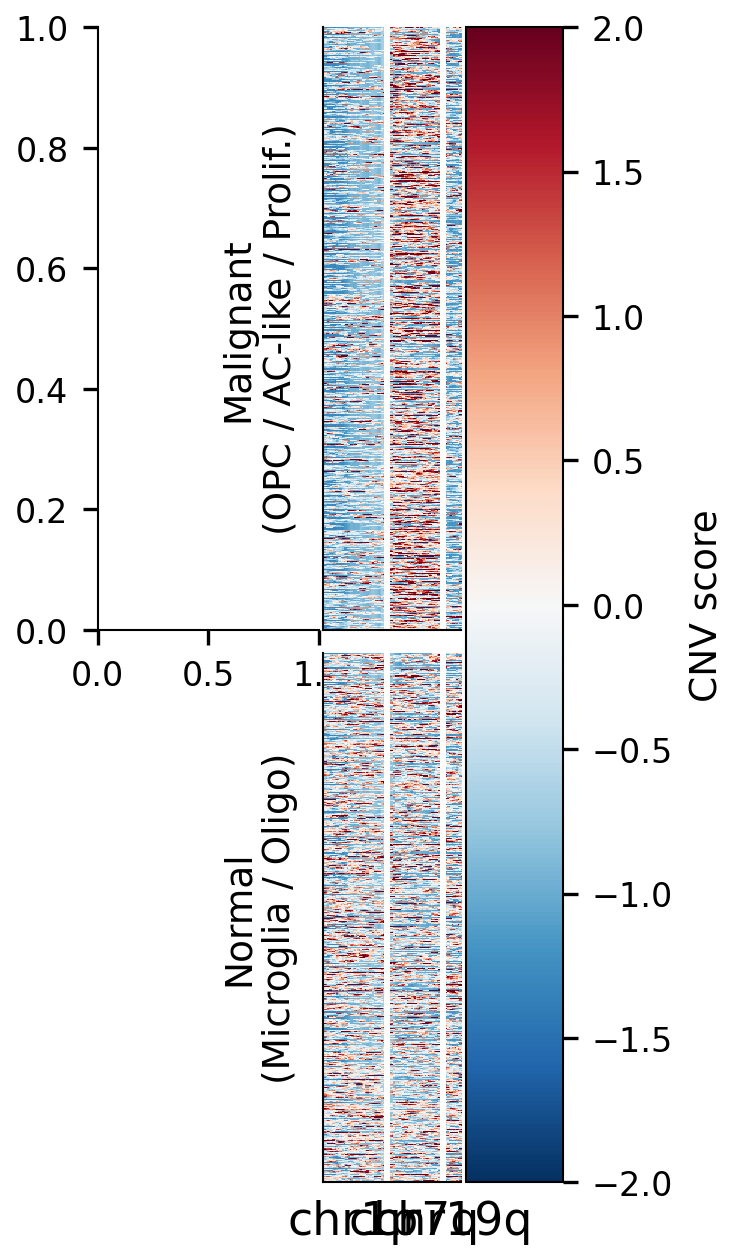

In [21]:
# loci to plot
mask1 = loci_df['chromosome'].isin(['chr1']) & loci_df['arm'].isin(['p'])
mask2 = loci_df['chromosome'].isin(['chr7']) & loci_df['arm'].isin(['q'])
mask3 = loci_df['chromosome'].isin(['chr19']) & loci_df['arm'].isin(['q'])

chr1_block = loci_df.loc[mask1, 'blockbin']
chr7_block = loci_df.loc[mask2, 'blockbin']
chr19_block = loci_df.loc[mask3, 'blockbin']

# ── data ──────────────────────────────────────────────────────────────────────
mask_mal  = corrected_loci['ROI'].isin([SAMPLE_ID]) & \
            corrected_loci['cell_type'].isin(['OPC', 'AC.like', 'OPC.like Prolif.'])
mask_norm = corrected_loci['ROI'].isin([SAMPLE_ID]) & \
            corrected_loci['cell_type'].isin(['Microglia', 'Oligo.normal'])

cols = list(chr1_block) + list(chr7_block) + list(chr19_block)
n1, n7, n19 = len(chr1_block), len(chr7_block), len(chr19_block)

data_mal  = corrected_loci.loc[mask_mal,  cols].to_numpy(dtype=float)
data_norm = corrected_loci.loc[mask_norm, cols].to_numpy(dtype=float)

# ── insert NaN gap columns between chromosome blocks ──────────────────────────
GAP_W = 4   # blank columns between blocks

def with_gaps(mat, sizes, gap=GAP_W):
    parts = []
    idx = 0
    for i, s in enumerate(sizes):
        parts.append(mat[:, idx:idx + s])
        if i < len(sizes) - 1:
            parts.append(np.full((mat.shape[0], gap), np.nan))
        idx += s
    return np.hstack(parts)

sizes = [n1, n7, n19]
mat_mal  = with_gaps(data_mal,  sizes)
mat_norm = with_gaps(data_norm, sizes)

# ── layout ─────────────────────────────────────────────────────────────────────
n_mal, n_norm = data_mal.shape[0], data_norm.shape[0]

fig = plt.figure(figsize=(2, 5))
gs = gridspec.GridSpec(
    2, 3,
    width_ratios  = [0.8, 0.5, 0.35],           # [dendrogram | heatmap | cbar]
    height_ratios = [n_mal, n_norm],            # proportional row heights
    hspace=0.04,
    wspace=0.03,
)

ax_dend = fig.add_subplot(gs[0, 0])
ax_mal  = fig.add_subplot(gs[0, 1])
ax_norm = fig.add_subplot(gs[1, 1])
ax_cbar = fig.add_subplot(gs[:, 2])
fig.add_subplot(gs[1, 0]).set_visible(False)   # blank below dendrogram


# ── heatmaps ──────────────────────────────────────────────────────────────────
cmap = plt.cm.RdBu_r.copy()
cmap.set_bad('white')                           # NaN gaps → white

im = ax_mal.imshow(mat_mal,  aspect='auto', cmap=cmap,
                   vmin=-2, vmax=2, interpolation='none')
ax_norm.imshow(mat_norm, aspect='auto', cmap=cmap,
                   vmin=-2, vmax=2, interpolation='none')

# remove all ticks
for ax in (ax_mal, ax_norm):
    ax.set_xticks([])
    ax.set_yticks([])

# ── chromosome block labels centred under each block ──────────────────────────
def centres(sizes, gap=GAP_W):
    out, idx = [], 0
    for s in sizes:
        out.append(idx + (s - 1) / 2)
        idx += s + gap
    return out

tick_pos    = centres(sizes)
block_names = ['chr1p', 'chr7q', 'chr19q']

ax_norm.set_xticks(tick_pos)
ax_norm.set_xticklabels(block_names, fontsize=11)
ax_norm.tick_params(axis='x', length=0, pad=4)

# ── row labels ────────────────────────────────────────────────────────────────
ax_mal.set_ylabel('Malignant\n(OPC / AC-like / Prolif.)', fontsize=9, labelpad=6)
ax_norm.set_ylabel('Normal\n(Microglia / Oligo)', fontsize=9, labelpad=6)

# ── colorbar ──────────────────────────────────────────────────────────────────
cb = plt.colorbar(im, cax=ax_cbar)
cb.set_label('CNV score', fontsize=9)

plt.savefig(f'{OUT_DIR}/Fig2_{SAMPLE_ID}_cnv_heatmap_combined.png', bbox_inches='tight', dpi=600)
plt.show()